#  Part 01 – Import required libraries

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Task 06 libraries imported successfully!")

Task 06 libraries imported successfully!


# Part 02 - Upload files

###If you are using a new notebook, upload your Task 05 files:
- X_test.csv
- y_test.csv
- 4 trained model files (.joblib)

In [3]:

from google.colab import files

uploaded = files.upload()


Saving Task05_ML_Results.zip to Task05_ML_Results.zip


In [4]:

from google.colab import files

uploaded = files.upload()


Saving y_test.csv to y_test.csv
Saving X_test.csv to X_test.csv


# Part 03-Evaluate all models

In [6]:
# Load the uploaded datasets
import os
import zipfile
import pandas as pd
import joblib
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Load data
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv')

# Ensure 1D shape for y_test if it is loaded as a DataFrame
if isinstance(y_test, pd.DataFrame):
    y_test = y_test.iloc[:, 0]

# 2. Extract and load models from the uploaded zip file
zip_path = 'Task05_ML_Results.zip'
extract_path = '/content/extracted_models'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Define output folders used in subsequent cells
evaluation_folder = '/content/evaluation_reports'
tables_folder = '/content/tables'
models_folder = '/content/models'
os.makedirs(evaluation_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)
os.makedirs(models_folder, exist_ok=True)

# Find and load the .joblib model files into best_models
best_models = {}
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith('.joblib') and file != 'best_model.joblib':
            model_name = os.path.splitext(file)[0].replace('_', ' ').title()
            model_path = os.path.join(root, file)
            best_models[model_name] = joblib.load(model_path)

print(f"Loaded models: {list(best_models.keys())}")

# 3. Calculate Accuracy, Precision, Recall, F1-score, and ROC-AUC
results = []

for model_name, model in best_models.items():
    y_pred = model.predict(X_test)

    # Basic metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # ROC-AUC
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_score)
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_test)
        roc_auc = roc_auc_score(y_test, y_score)
    else:
        roc_auc = np.nan

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': roc_auc
    })

evaluation_df = pd.DataFrame(results)
display(evaluation_df.round(4))

Loaded models: ['Random Forest Model', 'Logistic Regression Model', 'Decision Tree Model', 'Svm Model']


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest Model,0.640,0.6364,0.6364,0.6364,0.6672
1,Logistic Regression Model,0.610,0.6082,0.5960,0.6020,0.6336
2,Decision Tree Model,0.600,0.6173,0.5051,0.5556,0.6581
3,Svm Model,0.595,0.5978,0.5556,0.5759,0.6485


# Part 04-Generate confusion matrices

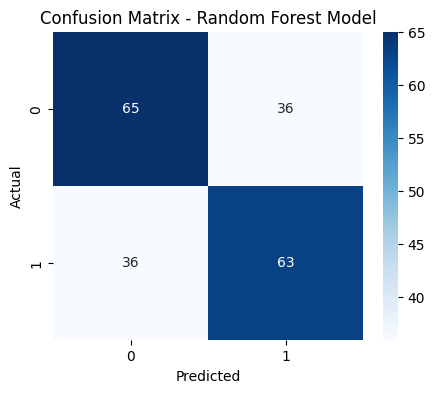

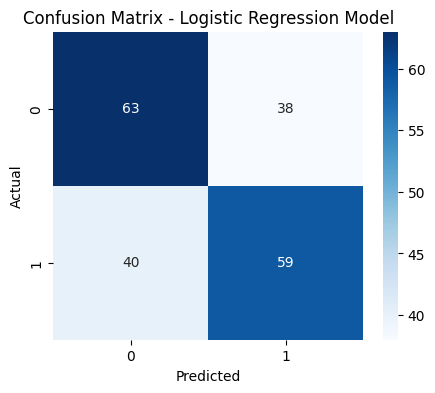

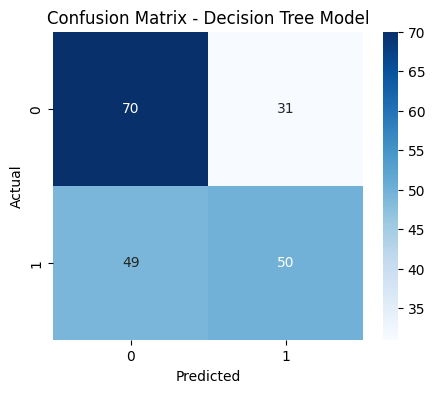

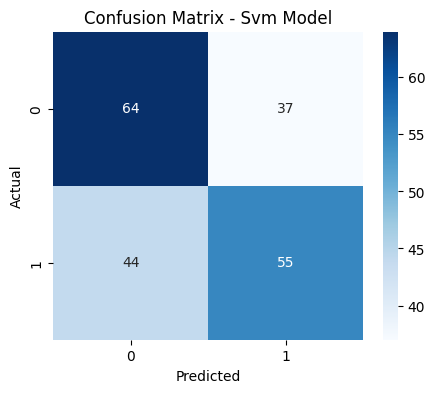

Confusion matrices saved!


In [7]:
#Create a confusion matrix for each model.

for model_name, model in best_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    filename = model_name.lower().replace(' ', '_') + '_confusion_matrix.png'

    plt.savefig(
        os.path.join(evaluation_folder, filename),
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

print("Confusion matrices saved!")

# Part 05-Compare models and identify the best model

In [8]:
#Select the best model based on the highest F1-score.

evaluation_df = evaluation_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(evaluation_df.round(4))

# Select best model
best_model_name = evaluation_df.iloc[0]['Model']
best_model = best_models[best_model_name]

print("Best Model:", best_model_name)
print(evaluation_df.iloc[0])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest Model,0.640,0.6364,0.6364,0.6364,0.6672
1,Logistic Regression Model,0.610,0.6082,0.5960,0.6020,0.6336
3,Svm Model,0.595,0.5978,0.5556,0.5759,0.6485
2,Decision Tree Model,0.600,0.6173,0.5051,0.5556,0.6581


Best Model: Random Forest Model
Model        Random Forest Model
Accuracy                    0.64
Precision               0.636364
Recall                  0.636364
F1 Score                0.636364
ROC-AUC                 0.667167
Name: 0, dtype: object


# Part 06-Save evaluation results and best model

In [9]:
# Save comparison table
evaluation_df.to_csv(
    os.path.join(tables_folder, 'task06_model_comparison.csv'),
    index=False
)

# Save best model
joblib.dump(
    best_model,
    os.path.join(models_folder, 'best_model.joblib')
)

print("Evaluation table and best model saved successfully!")

Evaluation table and best model saved successfully!


# Part 07-Download all evaluation files

In [11]:
import shutil
from google.colab import files as colab_files

download_folder = '/content/Task06_Output'

os.makedirs(download_folder, exist_ok=True)

# Copy evaluation table
shutil.copy2(
    os.path.join(tables_folder, 'task06_model_comparison.csv'),
    download_folder
)

# Copy figures
shutil.copytree(
    evaluation_folder,
    os.path.join(download_folder, 'figures'),
    dirs_exist_ok=True
)

# Copy best model
shutil.copy2(
    os.path.join(models_folder, 'best_model.joblib'),
    download_folder
)

# Create ZIP
zip_path = shutil.make_archive(
    '/content/Task06_Evaluation',
    'zip',
    download_folder
)

colab_files.download(zip_path)

print("Download started!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!


#